In [19]:
# 1. Mount Google Drive (This will trigger a permission popup in Colab)
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [21]:
base_path = "/content/drive/MyDrive/ML_Assignment/"

train_path = base_path + "Results/Outputs/final_preprocessed_train.csv"
test_path = base_path + "Results/Outputs/final_preprocessed_test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

In [22]:
# 4. Separate features and target
X = train_df.drop(columns=['SalePrice'])
y = np.log1p(train_df['SalePrice'])

In [23]:
# 5. Identify columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

In [24]:
# 6. Preprocessing engines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

In [25]:
# 7. Feature Selection Engine (Keeps top 50% most important features)
feature_selector = SelectFromModel(
    RandomForestRegressor(n_estimators=100, random_state=42),
    threshold='median'
)

In [26]:
# 8. Final Model
from sklearn.ensemble import RandomForestRegressor

# Replace your existing model definition with this updated version
rf_model = RandomForestRegressor(
    n_estimators=500,
    min_samples_split=5,
    max_features='sqrt',  # Updated from 1.0 to prevent overfitting
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

# Ensure this model is passed into your Pipeline definition right after this cell

In [27]:
# 9. Complete Pipeline
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('selector', feature_selector),
    ('model', rf_model)
])

In [39]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_validate

print("Running detailed 5-Fold Cross-Validation...")

# 1. Define the metrics
scoring_metrics = {
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

# 2. Run cross-validation
cv_results = cross_validate(
    pipeline,
    X,
    y,
    cv=5,
    scoring=scoring_metrics,
    return_train_score=True,
    n_jobs=-1
)

# 3. Format into the requested DataFrame
detailed_results = pd.DataFrame({
    'Fold': range(1, 6),
    'Train_RMSE': -cv_results['train_RMSE'],
    'Validation_RMSE': -cv_results['test_RMSE'],
    'Train_MAE': -cv_results['train_MAE'],
    'Validation_MAE': -cv_results['test_MAE'],
    'Train_R2': cv_results['train_R2'],
    'Validation_R2': cv_results['test_R2']
})

# 4. Save and display the final table
metrics_path = "/content/drive/MyDrive/ML_Assignment/Results/Outputs/new_random_forest_table_cv_detailed_table_.csv"
detailed_results.to_csv(metrics_path, index=False)

print(f"Detailed metrics saved successfully to: {metrics_path}\n")
display(detailed_results)

Running detailed 5-Fold Cross-Validation...
Detailed metrics saved successfully to: /content/drive/MyDrive/ML_Assignment/Results/Outputs/final_random_forest_table_cv_detailed_table_.csv



,Fold,Train_RMSE,Validation_RMSE,Train_MAE,Validation_MAE,Train_R2,Validation_R2
0,1,0.068601,0.127043,0.044823,0.086587,0.970936,0.891984
1,2,0.066494,0.154861,0.043408,0.098415,0.971313,0.867304
2,3,0.066583,0.145785,0.044078,0.093981,0.971818,0.873341
3,4,0.067909,0.130205,0.044646,0.087317,0.971663,0.882844
4,5,0.068059,0.142843,0.044182,0.095636,0.971239,0.866604


In [29]:
# 11. Train on FULL dataset for final predictions
print("Training on full dataset for final predictions...")
pipeline.fit(X, y)

Training on full dataset for final predictions...


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['OverallQual', 'TotalSF', 'GrLivArea', 'GarageCars', 'TotalBathrooms',
       'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd',
       'HouseAge', 'YearBuilt', 'YearsSinceRemodel', 'YearRemodAdd',
       'GarageYrBlt', 'MasVnr...
       'BsmtFinType2', 'Condition1', 'Alley', 'ExterCond', 'PoolQC',
       'LotConfig', 'Functional', 'Heating', 'MiscFeature', 'Condition2'],
      dtype='object'))])),
                ('selector',
                 SelectFromModel(estimator=RandomForestRegressor(random_state=42),
                                 threshold='median')),
                ('model',
                 RandomForestRegressor(max_depth=20, max_features='sqrt',
                                       min_samples_split=5, n_estimators=500,
                                       n_jobs=-1, random_state=42))])

In [32]:
# 1. Fit the pipeline on the ENTIRE dataset to maximize learning before predicting
print("Training final model on all data...")
pipeline.fit(X, y)

# 2. Load the preprocessed test dataset
test_path = "/content/drive/MyDrive/ML_Assignment/Results/Outputs/final_preprocessed_test.csv"
test_data = pd.read_csv(test_path)
X_test = test_data.copy()

# 3. Generate the IDs automatically (Ames Housing test IDs start at 1461)
test_ids = np.arange(1461, 1461 + len(X_test))

# 4. Generate predictions using your fitted pipeline
print("Generating predictions...")
log_predictions = pipeline.predict(X_test)

# 5. Reverse the log transformation to get actual dollar values
final_price_predictions = np.expm1(log_predictions)

# 6. Create the final submission file
submission = pd.DataFrame({
    'Id': test_ids,
    'SalePrice': final_price_predictions
})

# 7. Save the submission file directly to your Drive
submission_path = "/content/drive/MyDrive/ML_Assignment/Results/Outputs/new_random_forest_results_updated.csv"
submission.to_csv(submission_path, index=False)

print(f"Predictions generated and saved successfully to:\n{submission_path}")

Training final model on all data...
Generating predictions...
Predictions generated and saved successfully to:
/content/drive/MyDrive/ML_Assignment/Results/Outputs/final_random_forest_results_updated.csv


In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, r2_score

In [34]:
from sklearn.model_selection import train_test_split

# Recreate the validation split just for this evaluation block
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Generate predictions on the validation set
y_pred_log = pipeline.predict(X_valid)

# Convert predictions and actual values back to raw dollars from logs
y_pred_dollars = np.expm1(y_pred_log)
y_valid_dollars = np.expm1(y_valid)

In [35]:
# 1. Generate predictions on the validation set
y_pred_log = pipeline.predict(X_valid)

# Convert predictions and actual values back to raw dollars from logs
y_pred_dollars = np.expm1(y_pred_log)
y_valid_dollars = np.expm1(y_valid)

In [36]:
# 2. Calculate Evaluation Metrics
rmse_dollars = np.sqrt(mean_squared_error(y_valid_dollars, y_pred_dollars))
mae_dollars = mean_absolute_error(y_valid_dollars, y_pred_dollars)
r2 = r2_score(y_valid_dollars, y_pred_dollars)

print(f"--- Model Performance (Validation Set) ---")
print(f"R-squared (R²): {r2:.4f}")
print(f"Mean Absolute Error (MAE): ${mae_dollars:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse_dollars:,.2f}")
print(f"------------------------------------------\n")

--- Model Performance (Validation Set) ---
R-squared (R²): 0.9633
Mean Absolute Error (MAE): $8,555.78
Root Mean Squared Error (RMSE): $16,780.61
------------------------------------------



/tmp/ipykernel_738/4095766037.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df, x='Importance', y='Feature', ax=axes[2], palette='viridis')


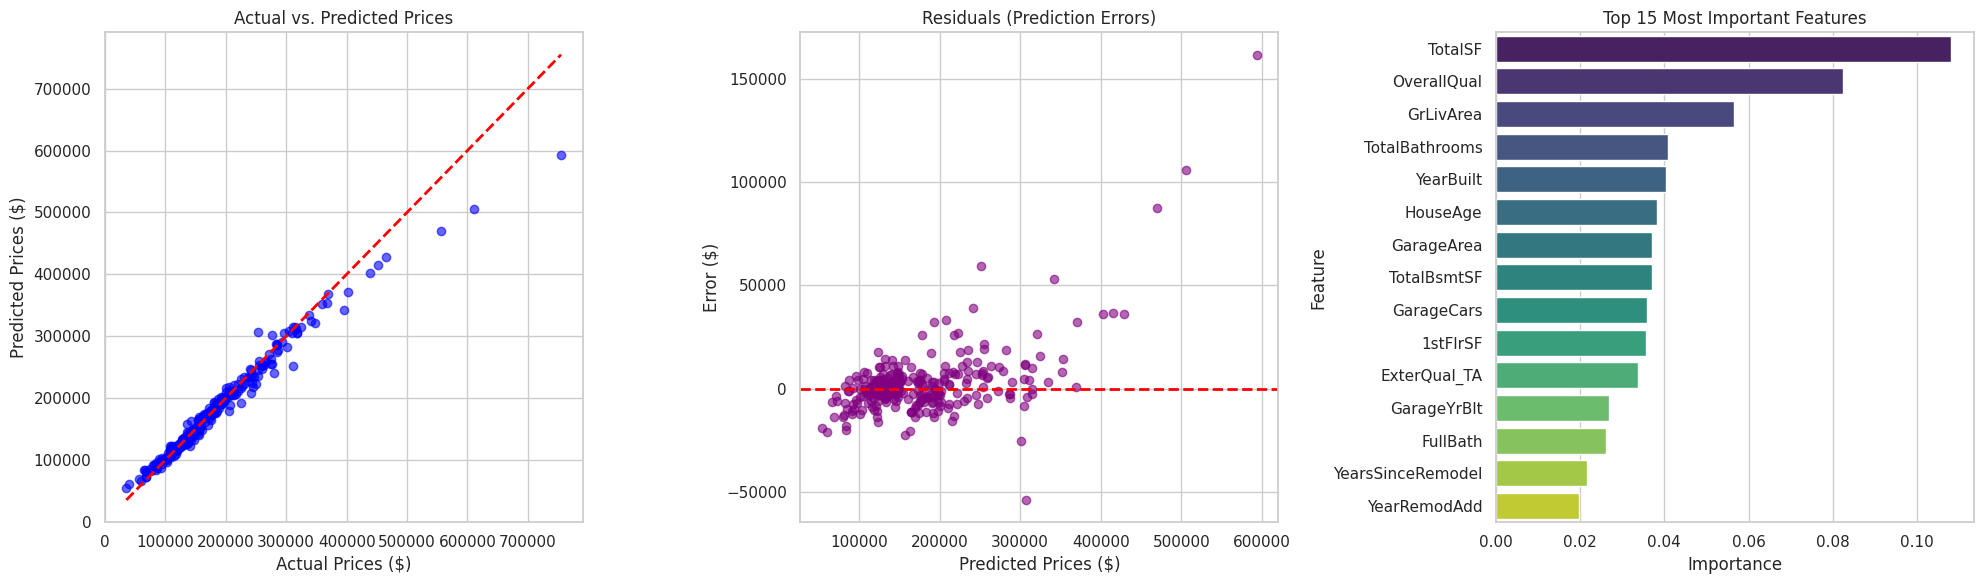

In [37]:
# Set up the visualization grid
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# --- PLOT 1: Actual vs. Predicted Prices ---
axes[0].scatter(y_valid_dollars, y_pred_dollars, alpha=0.6, color='blue')
axes[0].plot([y_valid_dollars.min(), y_valid_dollars.max()],
             [y_valid_dollars.min(), y_valid_dollars.max()],
             color='red', linestyle='--', lw=2)
axes[0].set_title('Actual vs. Predicted Prices')
axes[0].set_xlabel('Actual Prices ($)')
axes[0].set_ylabel('Predicted Prices ($)')

# --- PLOT 2: Residuals Plot (Errors) ---
# Residuals are the difference between actual and predicted
residuals = y_valid_dollars - y_pred_dollars
axes[1].scatter(y_pred_dollars, residuals, alpha=0.6, color='purple')
axes[1].axhline(y=0, color='red', linestyle='--', lw=2)
axes[1].set_title('Residuals (Prediction Errors)')
axes[1].set_xlabel('Predicted Prices ($)')
axes[1].set_ylabel('Error ($)')

# --- PLOT 3: Top 15 Feature Importances ---
# Extracting feature names and importances from the pipeline
try:
    # Get all feature names after One-Hot Encoding
    encoded_features = pipeline.named_steps['preprocessor'].get_feature_names_out()

    # Get the boolean mask of which features were kept by SelectFromModel
    kept_features_mask = pipeline.named_steps['selector'].get_support()

    # Filter to only the kept features
    kept_feature_names = encoded_features[kept_features_mask]

    # Get the actual importance scores from the Random Forest
    importances = pipeline.named_steps['model'].feature_importances_

    # Create a DataFrame and sort them
    feat_df = pd.DataFrame({
        'Feature': kept_feature_names,
        'Importance': importances
    }).sort_values(by='Importance', ascending=False).head(15)

    # Clean up feature names for display (removing 'num__' and 'cat__')
    feat_df['Feature'] = feat_df['Feature'].str.replace('num__', '').str.replace('cat__', '')

    sns.barplot(data=feat_df, x='Importance', y='Feature', ax=axes[2], palette='viridis')
    axes[2].set_title('Top 15 Most Important Features')
except Exception as e:
    axes[2].text(0.5, 0.5, 'Could not extract features.\nUpdate scikit-learn.',
                 ha='center', va='center')

plt.tight_layout()
plt.show()